In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Student": ["Arun", "Priya", "Kavin", "Divya", "Ravi"],
    "Classes_Attended": [55, 42, 35, 58, 48],
    "Total_Classes": [60, 60, 60, 60, 60]
}

df = pd.DataFrame(data)

df


,Student,Classes_Attended,Total_Classes
0,Arun,55,60
1,Priya,42,60
2,Kavin,35,60
3,Divya,58,60
4,Ravi,48,60


In [ ]:

df["Attendance_Percentage"] = (
    df["Classes_Attended"] / df["Total_Classes"] * 100
).round(2)

df


,Student,Classes_Attended,Total_Classes,Attendance_Percentage
0,Arun,55,60,91.67
1,Priya,42,60,70.00
2,Kavin,35,60,58.33
3,Divya,58,60,96.67
4,Ravi,48,60,80.00


In [ ]:

df["Risk_Status"] = df["Attendance_Percentage"].apply(
    lambda percentage: "At Risk"
    if percentage < 75
    else "Low Risk"
)

display(df)


,Student,Classes_Attended,Total_Classes,Attendance_Percentage,Risk_Status
0,Arun,55,60,91.67,Low Risk
1,Priya,42,60,70.00,At Risk
2,Kavin,35,60,58.33,At Risk
3,Divya,58,60,96.67,Low Risk
4,Ravi,48,60,80.00,Low Risk


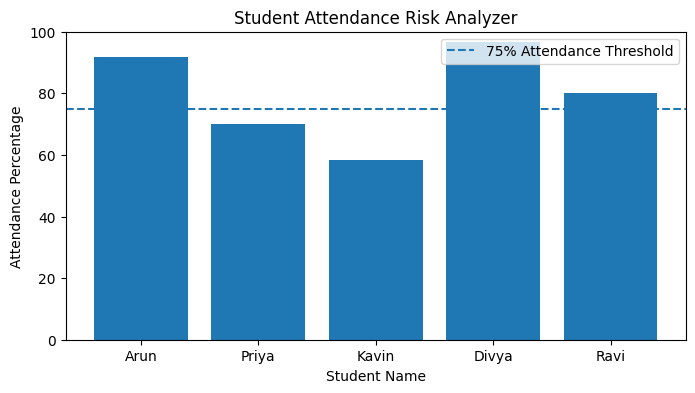

In [ ]:

plt.figure(figsize=(8, 4))

plt.bar(
    df["Student"],
    df["Attendance_Percentage"]
)

plt.axhline(
    y=75,
    linestyle="--",
    label="75% Attendance Threshold"
)

plt.xlabel("Student Name")
plt.ylabel("Attendance Percentage")
plt.title("Student Attendance Risk Analyzer")
plt.ylim(0, 100)
plt.legend()
plt.show()


In [ ]:

df.to_csv("attendance.csv", index=False)

from google.colab import files
files.download("attendance.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Student,Classes_Attended,Total_Classes,Attendance_Percentage,Risk_Status
0,Arun,55,60,91.67,Low Risk
1,Priya,42,60,70.00,At Risk
2,Kavin,35,60,58.33,At Risk
3,Divya,58,60,96.67,Low Risk
4,Ravi,48,60,80.00,Low Risk


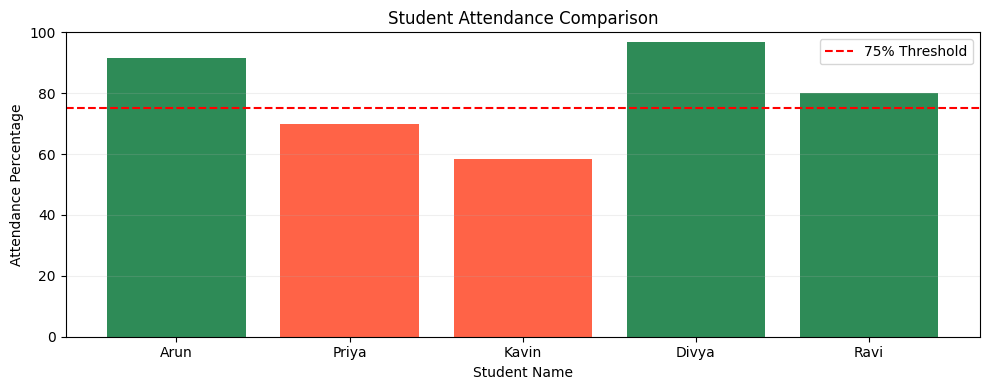

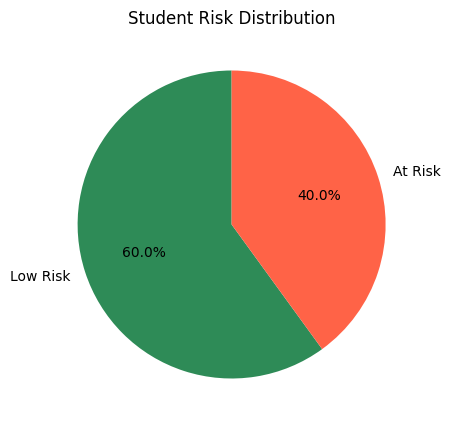

In [ ]:

# STUDENT ATTENDANCE RISK ANALYZER DASHBOARD

import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Calculate dashboard statistics
total_students = len(df)
at_risk = (df["Risk_Status"] == "At Risk").sum()
low_risk = (df["Risk_Status"] == "Low Risk").sum()
average_attendance = df["Attendance_Percentage"].mean()

# Dashboard heading and summary cards
display(HTML(f"""
<div style="font-family:Arial;background:#eaf2ff;
padding:22px;border-radius:12px;color:#17336b">
<h1>🎓 Student Attendance Risk Analyzer</h1>
<p>Student attendance monitoring dashboard</p>
<h3>Attendance Threshold: 75%</h3>
</div>

<div style="display:flex;flex-wrap:wrap;gap:12px;
font-family:Arial;margin:15px 0">

<div style="flex:1;min-width:140px;background:#dcecff;
padding:18px;border-radius:10px">
<h3>Total Students</h3>
<h1>{total_students}</h1>
</div>

<div style="flex:1;min-width:140px;background:#ffe0e5;
padding:18px;border-radius:10px">
<h3>Students At Risk</h3>
<h1 style="color:#d62728">{at_risk}</h1>
</div>

<div style="flex:1;min-width:140px;background:#dcfce7;
padding:18px;border-radius:10px">
<h3>Low Risk Students</h3>
<h1 style="color:#15803d">{low_risk}</h1>
</div>

<div style="flex:1;min-width:140px;background:#fff0c2;
padding:18px;border-radius:10px">
<h3>Average Attendance</h3>
<h1>{average_attendance:.2f}%</h1>
</div>
</div>

<h2 style="font-family:Arial;color:#17336b">
📋 Student Attendance Details</h2>
"""))

# Display the attendance table
display(df)

# Attendance bar chart
plt.figure(figsize=(10, 4))

bar_colors = [
    "tomato" if x < 75 else "seagreen"
    for x in df["Attendance_Percentage"]
]

plt.bar(
    df["Student"],
    df["Attendance_Percentage"],
    color=bar_colors
)

plt.axhline(
    y=75,
    color="red",
    linestyle="--",
    label="75% Threshold"
)

plt.ylim(0, 100)
plt.xlabel("Student Name")
plt.ylabel("Attendance Percentage")
plt.title("Student Attendance Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# Risk distribution pie chart
plt.figure(figsize=(5, 5))

plt.pie(
    [low_risk, at_risk],
    labels=["Low Risk", "At Risk"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["seagreen", "tomato"]
)

plt.title("Student Risk Distribution")
plt.show()

# Key insights
students_at_risk = df.loc[
    df["Risk_Status"] == "At Risk", "Student"
].tolist()

display(HTML(f"""
<div style="font-family:Arial;background:#eaf8ee;
padding:20px;border-radius:12px">
<h2 style="color:#166534">💡 Key Insights</h2>
<p>✅ Total students analyzed: {total_students}</p>
<p>⚠️ Students below 75%: {at_risk}</p>
<p>📊 Average attendance: {average_attendance:.2f}%</p>
<p>🎯 Students needing attention:
{", ".join(students_at_risk)}</p>
</div>
"""))


,Student,Classes_Attended,Total_Classes,Attendance_Percentage,Risk_Status
0,Arun,55,60,91.67%,Low Risk
1,Priya,42,60,70.00%,At Risk
2,Kavin,35,60,58.33%,At Risk
3,Divya,58,60,96.67%,Low Risk
4,Ravi,48,60,80.00%,Low Risk


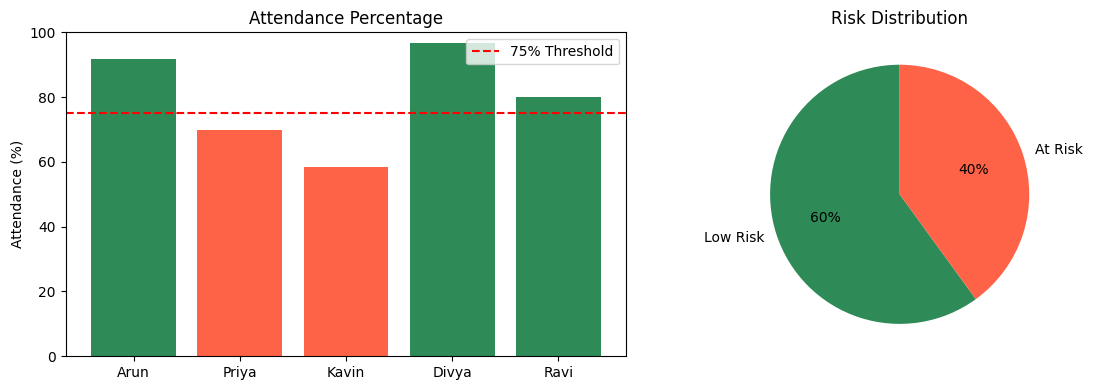

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Calculate dashboard information
threshold = 75
total = len(df)
at_risk = (df["Attendance_Percentage"] < threshold).sum()
low_risk = total - at_risk
average = df["Attendance_Percentage"].mean()

# Dashboard heading
display(HTML("""
<div style="background:#e8f1ff;padding:22px;border-radius:14px;
font-family:Arial;color:#17336b">
<h1>🎓 Student Attendance Risk Analyzer</h1>
<p>Attendance monitoring and early risk identification</p>
</div>
"""))

# Four dashboard cards
display(HTML(f"""
<div style="display:flex;flex-wrap:wrap;gap:12px;
font-family:Arial;margin:14px 0">

<div style="flex:1;min-width:140px;background:#e0edff;
padding:18px;border-radius:12px">
Total Students<h1>{total}</h1></div>

<div style="flex:1;min-width:140px;background:#ffe2e5;
padding:18px;border-radius:12px">
Students At Risk<h1 style="color:#c62828">{at_risk}</h1></div>

<div style="flex:1;min-width:140px;background:#dcfce7;
padding:18px;border-radius:12px">
Low Risk Students<h1 style="color:#15803d">{low_risk}</h1></div>

<div style="flex:1;min-width:140px;background:#fff1cc;
padding:18px;border-radius:12px">
Average Attendance<h1>{average:.2f}%</h1></div>

</div>
"""))

# Show student table
display(HTML("""
<h2 style="font-family:Arial;color:#17336b">
📋 Student Attendance Details</h2>
"""))

display(
    df.style.format({"Attendance_Percentage": "{:.2f}%"})
    .map(
        lambda x: "color:red;font-weight:bold"
        if x == "At Risk" else "color:green;font-weight:bold",
        subset=["Risk_Status"]
    )
)

# Put two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bar_colors = [
    "tomato" if x < threshold else "seagreen"
    for x in df["Attendance_Percentage"]
]

axes[0].bar(
    df["Student"],
    df["Attendance_Percentage"],
    color=bar_colors
)
axes[0].axhline(
    threshold, color="red", linestyle="--",
    label="75% Threshold"
)
axes[0].set_ylim(0, 100)
axes[0].set_title("Attendance Percentage")
axes[0].set_ylabel("Attendance (%)")
axes[0].legend()

axes[1].pie(
    [low_risk, at_risk],
    labels=["Low Risk", "At Risk"],
    autopct="%1.0f%%",
    colors=["seagreen", "tomato"],
    startangle=90
)
axes[1].set_title("Risk Distribution")

plt.tight_layout()
plt.show()

# Key insights
names = df.loc[
    df["Risk_Status"] == "At Risk", "Student"
].tolist()

display(HTML(f"""
<div style="background:#eaf8ee;padding:20px;
border-radius:12px;font-family:Arial">
<h2 style="color:#166534">💡 Key Insights</h2>
<p>✅ Students analyzed: {total}</p>
<p>⚠️ Students below {threshold}% attendance: {at_risk}</p>
<p>📊 Average attendance: {average:.2f}%</p>
<p>🎯 Students needing attention: {", ".join(names)}</p>
</div>
"""))


In [ ]:

import pandas as pd

data = {
    "Student": ["Arun", "Priya", "Kavin", "Divya", "Ravi"],
    "Classes_Attended": [55, 42, 35, 58, 48],
    "Total_Classes": [60, 60, 60, 60, 60]
}

df = pd.DataFrame(data)

df.to_csv("attendance.csv", index=False)

print("CSV file created successfully!")
display(df)


CSV file created successfully!


,Student,Classes_Attended,Total_Classes
0,Arun,55,60
1,Priya,42,60
2,Kavin,35,60
3,Divya,58,60
4,Ravi,48,60


In [ ]:

import pandas as pd

# Read student data from the CSV file
df = pd.read_csv("attendance.csv")

# Calculate attendance percentage
df["Attendance_Percentage"] = (
    df["Classes_Attended"] / df["Total_Classes"]
) * 100

# Identify attendance risk
df["Risk_Status"] = df["Attendance_Percentage"].apply(
    lambda x: "At Risk" if x < 75 else "Low Risk"
)

# Display the result
display(df)

print("Average Attendance:", round(
    df["Attendance_Percentage"].mean(), 2), "%")

print("Students At Risk:",
      (df["Risk_Status"] == "At Risk").sum())


,Student,Classes_Attended,Total_Classes,Attendance_Percentage,Risk_Status
0,Arun,55,60,91.666667,Low Risk
1,Priya,42,60,70.000000,At Risk
2,Kavin,35,60,58.333333,At Risk
3,Divya,58,60,96.666667,Low Risk
4,Ravi,48,60,80.000000,Low Risk


Average Attendance: 79.33 %
Students At Risk: 2


In [11]:
!pip -q install boto3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 7.2 MB/s eta 0:00:00


In [12]:

import boto3
import getpass

access_key = getpass.getpass("Enter AWS Access Key ID: ")
secret_key = getpass.getpass("Enter AWS Secret Access Key: ")
session_token = getpass.getpass("Enter AWS Session Token: ")

region = input("Enter your S3 bucket region (example: us-west-2): ").strip()

s3 = boto3.client(
    "s3",
    aws_access_key_id=access_key,
    aws_secret_access_key=secret_key,
    aws_session_token=session_token,
    region_name=region
)

print("AWS connection setup completed!")


Enter AWS Access Key ID: ··········
Enter AWS Secret Access Key: ··········
Enter AWS Session Token: ··········
Enter your S3 bucket region (example: us-west-2): us-east-1
AWS connection setup completed!


In [13]:

# Check the AWS connection
response = s3.list_buckets()

print("AWS connection verified!")
print("Available S3 buckets:")

for bucket_info in response["Buckets"]:
    print("-", bucket_info["Name"])


AWS connection verified!
Available S3 buckets:
- student-attendance-risk-2026


In [14]:

import pandas as pd

bucket_name = input("Enter your S3 bucket name: ").strip()

response = s3.list_objects_v2(Bucket=bucket_name)
print("Files in bucket:")

for obj in response.get("Contents", []):
    print("-", obj["Key"])


Enter your S3 bucket name: student-attendance-risk-2026
Files in bucket:
- attendance (1).csv


In [15]:

import pandas as pd

file_name = "attendance (1).csv"

obj = s3.get_object(
    Bucket=bucket_name,
    Key=file_name
)

df = pd.read_csv(obj["Body"])

print("Attendance data loaded successfully from AWS S3!")
display(df)


Attendance data loaded successfully from AWS S3!


,Student,Classes_Attended,Total_Classes,Attendance_Percentage,Risk_Status
0,Arun,55,60,91.67,Low Risk
1,Priya,42,60,70.00,At Risk
2,Kavin,35,60,58.33,At Risk
3,Divya,58,60,96.67,Low Risk
4,Ravi,48,60,80.00,Low Risk


In [16]:

# Analyze attendance data loaded from AWS S3

total_students = len(df)
at_risk = (df["Attendance_Percentage"] < 75).sum()
low_risk = total_students - at_risk
average_attendance = df["Attendance_Percentage"].mean()

print("STUDENT ATTENDANCE RISK ANALYZER")
print("-" * 35)
print("Total Students:", total_students)
print("Average Attendance:", round(average_attendance, 2), "%")
print("Students At Risk:", at_risk)
print("Students with Low Risk:", low_risk)

print("\nStudents who need attention:")
display(df[df["Attendance_Percentage"] < 75])


STUDENT ATTENDANCE RISK ANALYZER
-----------------------------------
Total Students: 5
Average Attendance: 79.33 %
Students At Risk: 2
Students with Low Risk: 3

Students who need attention:


,Student,Classes_Attended,Total_Classes,Attendance_Percentage,Risk_Status
1,Priya,42,60,70.00,At Risk
2,Kavin,35,60,58.33,At Risk


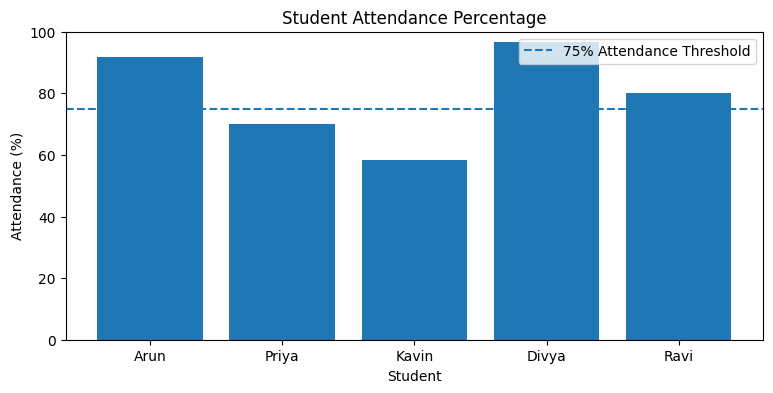

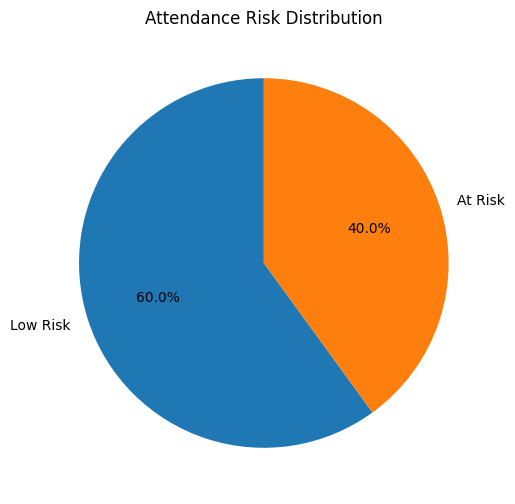

,Student,Classes_Attended,Total_Classes,Attendance_Percentage,Risk_Status
0,Arun,55,60,91.67,Low Risk
1,Priya,42,60,70.00,At Risk
2,Kavin,35,60,58.33,At Risk
3,Divya,58,60,96.67,Low Risk
4,Ravi,48,60,80.00,Low Risk


In [17]:

import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Calculate results using the data loaded from AWS S3
total_students = len(df)
average_attendance = df["Attendance_Percentage"].mean()
at_risk = (df["Risk_Status"] == "At Risk").sum()
low_risk = total_students - at_risk

# Dashboard summary
display(HTML(f"""
<h1 style="text-align:center;">Student Attendance Risk Analyzer</h1>
<p style="text-align:center;">
Cloud Data Source: AWS S3 | Analysis: Python & Pandas
</p>
<div style="display:flex; gap:12px; flex-wrap:wrap;">
  <div style="background:#e8f0fe;padding:18px;border-radius:10px;flex:1">
    <b>Total Students</b><h2>{total_students}</h2>
  </div>
  <div style="background:#e6f4ea;padding:18px;border-radius:10px;flex:1">
    <b>Average Attendance</b><h2>{average_attendance:.2f}%</h2>
  </div>
  <div style="background:#fce8e6;padding:18px;border-radius:10px;flex:1">
    <b>At Risk</b><h2>{at_risk}</h2>
  </div>
  <div style="background:#fff4ce;padding:18px;border-radius:10px;flex:1">
    <b>Low Risk</b><h2>{low_risk}</h2>
  </div>
</div>
"""))

# Attendance bar chart
plt.figure(figsize=(9, 4))
plt.bar(df["Student"], df["Attendance_Percentage"])
plt.axhline(y=75, linestyle="--", label="75% Attendance Threshold")
plt.title("Student Attendance Percentage")
plt.xlabel("Student")
plt.ylabel("Attendance (%)")
plt.ylim(0, 100)
plt.legend()
plt.show()

# Risk distribution pie chart
risk_counts = df["Risk_Status"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(risk_counts.values, labels=risk_counts.index,
        autopct="%1.1f%%", startangle=90)
plt.title("Attendance Risk Distribution")
plt.show()

# Show the final attendance table
display(df)


In [18]:

# Final cloud integration verification

import pandas as pd

# Reload the latest CSV directly from AWS S3
obj = s3.get_object(
    Bucket=bucket_name,
    Key="attendance (1).csv"
)

cloud_df = pd.read_csv(obj["Body"])

# Recalculate risk status using the 75% threshold
cloud_df["Attendance_Percentage"] = (
    cloud_df["Classes_Attended"] / cloud_df["Total_Classes"] * 100
).round(2)

cloud_df["Risk_Status"] = cloud_df["Attendance_Percentage"].apply(
    lambda x: "At Risk" if x < 75 else "Low Risk"
)

print("SUCCESS: Data retrieved directly from AWS S3")
print("Total students:", len(cloud_df))
print("At-risk students:", (cloud_df["Risk_Status"] == "At Risk").sum())
print("Average attendance:",
      round(cloud_df["Attendance_Percentage"].mean(), 2), "%")

display(cloud_df)


SUCCESS: Data retrieved directly from AWS S3
Total students: 5
At-risk students: 2
Average attendance: 79.33 %


,Student,Classes_Attended,Total_Classes,Attendance_Percentage,Risk_Status
0,Arun,55,60,91.67,Low Risk
1,Priya,42,60,70.00,At Risk
2,Kavin,35,60,58.33,At Risk
3,Divya,58,60,96.67,Low Risk
4,Ravi,48,60,80.00,Low Risk


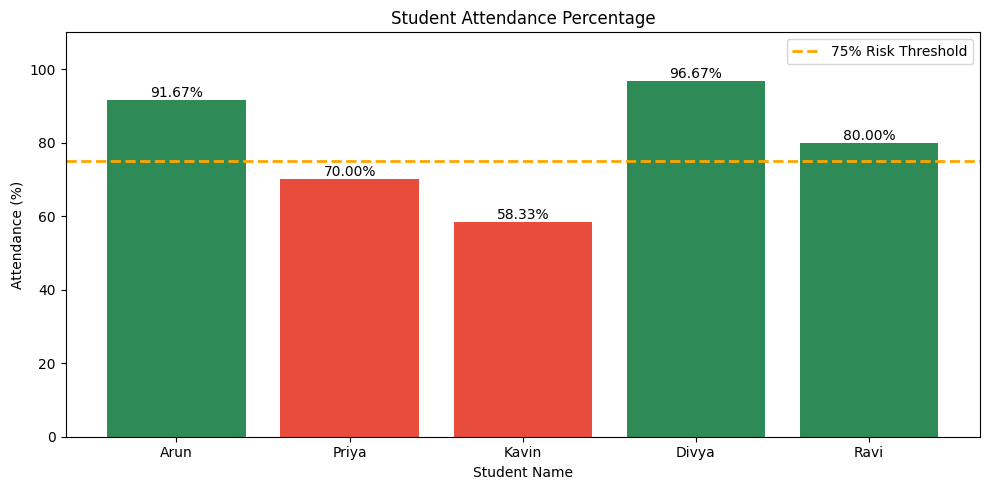

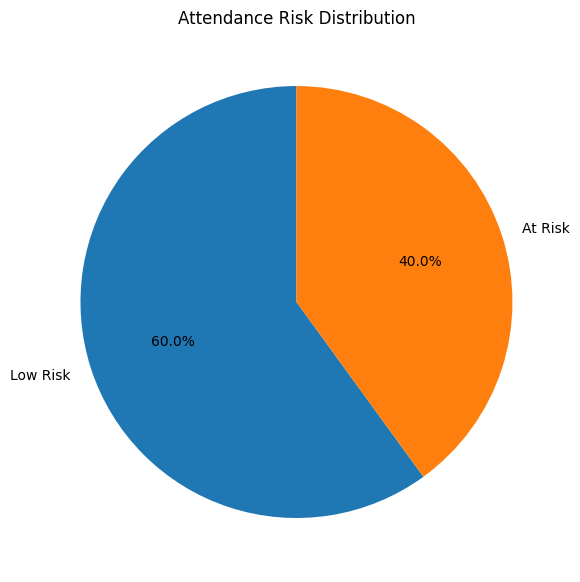

,Student,Classes_Attended,Total_Classes,Attendance_Percentage,Risk_Status
0,Arun,55,60,91.67,Low Risk
1,Priya,42,60,70.00,At Risk
2,Kavin,35,60,58.33,At Risk
3,Divya,58,60,96.67,Low Risk
4,Ravi,48,60,80.00,Low Risk



KEY INSIGHTS
-----------------------------------
Total students: 5
Average attendance: 79.33%
Students at risk: 2
Students with low risk: 3

Students who need attention:


,Student,Attendance_Percentage,Risk_Status
1,Priya,70.00,At Risk
2,Kavin,58.33,At Risk


In [19]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Use the attendance data loaded from AWS S3
dashboard_df = df.copy()

# Calculate attendance percentage if needed
dashboard_df["Attendance_Percentage"] = (
    dashboard_df["Classes_Attended"] /
    dashboard_df["Total_Classes"] * 100
).round(2)

# Identify attendance risk: below 75% is At Risk
dashboard_df["Risk_Status"] = dashboard_df["Attendance_Percentage"].apply(
    lambda x: "At Risk" if x < 75 else "Low Risk"
)

# Calculate dashboard metrics
total_students = len(dashboard_df)
average_attendance = dashboard_df["Attendance_Percentage"].mean()
at_risk = (dashboard_df["Risk_Status"] == "At Risk").sum()
low_risk = total_students - at_risk

# Dashboard heading and summary cards
display(HTML(f"""
<div style="font-family:Arial; padding:15px;">
    <h1 style="text-align:center;">
        Student Attendance Risk Analyzer
    </h1>
    <p style="text-align:center; color:gray;">
        Cloud Data Source: AWS S3 | Python, Pandas and Matplotlib
    </p>

    <div style="display:flex; flex-wrap:wrap; gap:12px;">
        <div style="background:#e8f0fe; padding:18px;
                    border-radius:10px; flex:1; min-width:130px;">
            <b>Total Students</b>
            <h2>{total_students}</h2>
        </div>

        <div style="background:#e6f4ea; padding:18px;
                    border-radius:10px; flex:1; min-width:130px;">
            <b>Average Attendance</b>
            <h2>{average_attendance:.2f}%</h2>
        </div>

        <div style="background:#fce8e6; padding:18px;
                    border-radius:10px; flex:1; min-width:130px;">
            <b>At Risk</b>
            <h2>{at_risk}</h2>
        </div>

        <div style="background:#fff4ce; padding:18px;
                    border-radius:10px; flex:1; min-width:130px;">
            <b>Low Risk</b>
            <h2>{low_risk}</h2>
        </div>
    </div>
</div>
"""))

# Chart 1: Student attendance percentages
plt.figure(figsize=(10, 5))

bars = plt.bar(
    dashboard_df["Student"],
    dashboard_df["Attendance_Percentage"],
    color=[
        "#2e8b57" if x >= 75 else "#e74c3c"
        for x in dashboard_df["Attendance_Percentage"]
    ]
)

plt.axhline(
    y=75,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="75% Risk Threshold"
)

plt.bar_label(bars, fmt="%.2f%%")
plt.title("Student Attendance Percentage")
plt.xlabel("Student Name")
plt.ylabel("Attendance (%)")
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.show()

# Chart 2: Attendance risk distribution
risk_counts = dashboard_df["Risk_Status"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    risk_counts.values,
    labels=risk_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Attendance Risk Distribution")
plt.tight_layout()
plt.show()

# Final attendance table
display(HTML("<h2>Student Attendance Records</h2>"))
display(dashboard_df)

# Key insights
print("\nKEY INSIGHTS")
print("-" * 35)
print(f"Total students: {total_students}")
print(f"Average attendance: {average_attendance:.2f}%")
print(f"Students at risk: {at_risk}")
print(f"Students with low risk: {low_risk}")

print("\nStudents who need attention:")
display(
    dashboard_df[
        dashboard_df["Risk_Status"] == "At Risk"
    ][["Student", "Attendance_Percentage", "Risk_Status"]]
)
